**https://zenodo.org/records/14223441**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import warnings
warnings.filterwarnings('ignore')

In [ ]:
adult_data=pd.read_csv("cleaned_adult_income.csv")

In [ ]:
adult_data.head()

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income,age_group
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K,18-30
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K,30-40
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K,18-30
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K,40-50
4,34,Private,198693,10th,6,Never-married,Other-service,Not-in-family,White,Male,0,0,30,United-States,<=50K,30-40


In [ ]:
adult_data.shape

(45222, 16)

In [ ]:
adult_data.sample(40)

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income,age_group
478,30,Local-gov,176992,HS-grad,9,Married-civ-spouse,Transport-moving,Husband,White,Male,0,0,50,United-States,>50K,30-40
27522,42,Self-emp-not-inc,336513,Bachelors,13,Married-civ-spouse,Craft-repair,Husband,White,Male,15024,0,60,United-States,>50K,40-50
36929,47,Local-gov,219632,Assoc-acdm,12,Separated,Exec-managerial,Not-in-family,White,Male,0,1408,40,United-States,<=50K,40-50
4545,53,Private,173020,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,60,United-States,>50K,50-60
36569,24,Private,464103,HS-grad,9,Never-married,Adm-clerical,Not-in-family,White,Male,0,0,50,United-States,<=50K,18-30
7477,46,Private,172155,Bachelors,13,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,Peru,<=50K,40-50
29526,43,Private,220109,Some-college,10,Married-civ-spouse,Other-service,Husband,White,Male,0,1672,44,United-States,<=50K,40-50
14637,42,Private,191429,HS-grad,9,Married-civ-spouse,Sales,Husband,White,Male,15024,0,60,United-States,>50K,40-50
14649,50,Self-emp-inc,207841,Some-college,10,Married-civ-spouse,Exec-managerial,Husband,White,Male,7298,0,45,United-States,>50K,50-60
5987,35,Private,194496,Bachelors,13,Married-civ-spouse,Sales,Husband,White,Male,0,0,55,United-States,<=50K,30-40


In [ ]:
adult_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45222 entries, 0 to 45221
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   age              45222 non-null  int64 
 1   workclass        45222 non-null  object
 2   fnlwgt           45222 non-null  int64 
 3   education        45222 non-null  object
 4   educational-num  45222 non-null  int64 
 5   marital-status   45222 non-null  object
 6   occupation       45222 non-null  object
 7   relationship     45222 non-null  object
 8   race             45222 non-null  object
 9   gender           45222 non-null  object
 10  capital-gain     45222 non-null  int64 
 11  capital-loss     45222 non-null  int64 
 12  hours-per-week   45222 non-null  int64 
 13  native-country   45222 non-null  object
 14  income           45222 non-null  object
 15  age_group        45222 non-null  object
dtypes: int64(6), object(10)
memory usage: 5.5+ MB


In [ ]:
adult_data.isnull().sum()

,0
age,0
workclass,0
fnlwgt,0
education,0
educational-num,0
marital-status,0
occupation,0
relationship,0
race,0
gender,0


In [ ]:
print("Initial Shape:", adult_data.shape)

duplicate_count = adult_data.duplicated().sum()
print("Duplicate Rows:", duplicate_count)

df = adult_data.drop_duplicates()

print("Final Shape after removing duplicates:", df.shape)

Initial Shape: (45222, 16)
Duplicate Rows: 47
Final Shape after removing duplicates: (45175, 16)


In [ ]:
df.describe()

,age,fnlwgt,educational-num,capital-gain,capital-loss,hours-per-week
count,45175.000000,4.517500e+04,45175.000000,45175.000000,45175.000000,45175.000000
mean,38.556170,1.897388e+05,10.119314,1102.576270,88.687593,40.942512
std,13.215349,1.056524e+05,2.551740,7510.249876,405.156611,12.007730
min,17.000000,1.349200e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.173925e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783120e+05,10.000000,0.000000,0.000000,40.000000
75%,47.000000,2.379030e+05,13.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


In [ ]:
for col in df.select_dtypes(include='object').columns:
    print(f"\nColumn: {col}")
    print(df[col].unique()[:10])


Column: workclass
['Private' 'Local-gov' 'Self-emp-not-inc' 'Federal-gov' 'State-gov'
 'Self-emp-inc' 'Without-pay']

Column: education
['11th' 'HS-grad' 'Assoc-acdm' 'Some-college' '10th' 'Prof-school'
 '7th-8th' 'Bachelors' 'Masters' '5th-6th']

Column: marital-status
['Never-married' 'Married-civ-spouse' 'Widowed' 'Separated' 'Divorced'
 'Married-spouse-absent' 'Married-AF-spouse']

Column: occupation
['Machine-op-inspct' 'Farming-fishing' 'Protective-serv' 'Other-service'
 'Prof-specialty' 'Craft-repair' 'Adm-clerical' 'Exec-managerial'
 'Tech-support' 'Sales']

Column: relationship
['Own-child' 'Husband' 'Not-in-family' 'Unmarried' 'Wife' 'Other-relative']

Column: race
['Black' 'White' 'Other' 'Amer-Indian-Eskimo' 'Asian-Pac-Islander']

Column: gender
['Male' 'Female']

Column: native-country
['United-States' 'Peru' 'Guatemala' 'Mexico' 'Dominican-Republic'
 'Ireland' 'Germany' 'Philippines' 'Thailand' 'Haiti']

Column: income
['<=50K' '>50K']

Column: age_group
['18-30' '30-40'

In [ ]:
print(df["income"].value_counts())
print(df["income"].value_counts(normalize=True) * 100)

income
<=50K    33973
>50K     11202
Name: count, dtype: int64
income
<=50K    75.203099
>50K     24.796901
Name: proportion, dtype: float64


In [ ]:
numerical_columns = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_columns = df.select_dtypes(include=["object"]).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)

Numerical Columns:
['age', 'fnlwgt', 'educational-num', 'capital-gain', 'capital-loss', 'hours-per-week']

Categorical Columns:
['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'gender', 'native-country', 'income', 'age_group']


**Univariate analysis**

In [ ]:
income_percent = (df["income"].value_counts(normalize=True) * 100).reset_index()
income_percent.columns = ["income", "percentage"]

fig = px.pie(
    income_percent,
    names="income",
    values="percentage",
    hole=0.5,
    color="income",
    color_discrete_sequence=["#9b59b6", "#f1c40f"],
    title="Income Percentage Distribution"
)

fig.update_traces(
    textinfo="percent+label",
    marker=dict(line=dict(color="white", width=2))
)

fig.update_layout(
    paper_bgcolor="#1e1e2f",
    font=dict(color="white", size=14),
    title_font=dict(size=22, color="#f1c40f")
)

fig.show()

In [ ]:
fig = px.histogram(
    df,
    x="age",
    nbins=30,
    title="Distribution of Age",
    marginal="violin",
    color_discrete_sequence=["#00FFFF"]
)

fig.update_traces(marker_line_color="black", marker_line_width=1)

fig.update_layout(
    plot_bgcolor="#0f172a",
    paper_bgcolor="#0f172a",
    font=dict(color="white"),
    title_font=dict(size=22, color="#00FFFF"),
    xaxis_title="Age",
    yaxis_title="Frequency",
    yaxis=dict(gridcolor="#334155"),
    xaxis=dict(gridcolor="#334155")
)

fig.show()

In [ ]:
workclass_counts = df["workclass"].value_counts().reset_index()
workclass_counts.columns = ["workclass", "count"]

fig = px.bar(
    workclass_counts,
    x="count",
    y="workclass",
    orientation="h",
    text="count",
    color="count",
    color_continuous_scale="YlOrBr",
    title="Distribution of Workclass"
)

fig.update_layout(
    plot_bgcolor="#1c1917",
    paper_bgcolor="#1c1917",
    font=dict(color="#fef3c7"),
    title_font=dict(size=22, color="#facc15"),
    xaxis_title="Count",
    yaxis_title="Workclass"
)

fig.show()

In [ ]:
education_counts = df["education"].value_counts().reset_index()
education_counts.columns = ["education", "count"]

fig = px.bar(
    education_counts,
    x="education",
    y="count",
    text="count",
    color="count",
    color_continuous_scale="Tealgrn",
    title="Distribution of Education Levels"
)

fig.update_traces(textposition="outside")

fig.update_layout(
    plot_bgcolor="#042f2e",
    paper_bgcolor="#042f2e",
    font=dict(color="#ccfbf1"),
    title_font=dict(size=22, color="#14b8a6"),
    xaxis_title="Education",
    yaxis_title="Count",
    xaxis_tickangle=-45
)

fig.show()

In [ ]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go

fig = make_subplots(
    rows=3,
    cols=3,
    subplot_titles=[
        "fnlwgt Distribution",
        "Educational Number Distribution",
        "Capital Gain Distribution",
        "Capital Loss Distribution",
        "Hours Per Week Distribution",
        "Gender Distribution",
        "Race Distribution",
        "Top 10 Native Countries"
    ],
    specs=[
        [{"type": "histogram"}, {"type": "histogram"}, {"type": "histogram"}],
        [{"type": "histogram"}, {"type": "histogram"}, {"type": "bar"}],
        [{"type": "bar"}, {"type": "bar"}, None]  # last cell removed
    ]
)

main_color = "#FFD700"
bg_color = "black"
font_color = "yellow"
grid_color = "#444444"
line_color = "white"

# fnlwgt
fig.add_trace(
    go.Histogram(x=df["fnlwgt"], nbinsx=40,
                 marker=dict(color=main_color, line=dict(color=line_color, width=1))),
    row=1, col=1
)

# Educational Number
fig.add_trace(
    go.Histogram(x=df["educational-num"], nbinsx=20,
                 marker=dict(color=main_color, line=dict(color=line_color, width=1))),
    row=1, col=2
)

# Capital Gain
fig.add_trace(
    go.Histogram(x=df["capital-gain"], nbinsx=40,
                 marker=dict(color=main_color, line=dict(color=line_color, width=1))),
    row=1, col=3
)

# Capital Loss
fig.add_trace(
    go.Histogram(x=df["capital-loss"], nbinsx=40,
                 marker=dict(color=main_color, line=dict(color=line_color, width=1))),
    row=2, col=1
)

# Hours Per Week
fig.add_trace(
    go.Histogram(x=df["hours-per-week"], nbinsx=30,
                 marker=dict(color=main_color, line=dict(color=line_color, width=1))),
    row=2, col=2
)

# Gender
gender_counts = df["gender"].value_counts()
fig.add_trace(
    go.Bar(x=gender_counts.index, y=gender_counts.values,
           marker=dict(color=main_color, line=dict(color=line_color, width=1.5)),
           text=gender_counts.values, textposition="outside"),
    row=2, col=3
)

# Race
race_counts = df["race"].value_counts()
fig.add_trace(
    go.Bar(x=race_counts.index, y=race_counts.values,
           marker=dict(color=main_color, line=dict(color=line_color, width=1.5)),
           text=race_counts.values, textposition="outside"),
    row=3, col=1
)

# Native Country
country_counts = df["native-country"].value_counts().head(10)
fig.add_trace(
    go.Bar(x=country_counts.index, y=country_counts.values,
           marker=dict(color=main_color, line=dict(color=line_color, width=1.5)),
           text=country_counts.values, textposition="outside"),
    row=3, col=2
)

fig.update_layout(
    height=1200,
    width=1200,
    title_text="Univariate Analysis of Adult Income Dataset",
    title_font=dict(size=26, color=font_color),
    paper_bgcolor=bg_color,
    plot_bgcolor=bg_color,
    font=dict(color=font_color),
    showlegend=False
)

fig.update_xaxes(showgrid=False, tickangle=-45, color=font_color)
fig.update_yaxes(showgrid=True, gridcolor=grid_color, color=font_color)

fig.show()

**Bivariate Analysis**

In [ ]:
fig = px.box(
    df,
    x="income",
    y="age",
    color="income",
    color_discrete_sequence=["#ff6b6b", "#4ecdc4"],
    title="Age Distribution by Income"
)

fig.update_layout(
    plot_bgcolor="#0a0a0a",
    paper_bgcolor="#0a0a0a",
    font=dict(color="white"),
    title_font=dict(size=22, color="#ff6b6b")
)

fig.show()

In [ ]:
edu_income = pd.crosstab(df["education"], df["income"])

fig = px.bar(
    edu_income,
    barmode="stack",
    color_discrete_sequence=["#ff9f43", "#1dd1a1"],
    title="Education vs Income"
)

fig.update_layout(
    plot_bgcolor="#111827",
    paper_bgcolor="#111827",
    font=dict(color="white"),
    xaxis_tickangle=-45
)

fig.show()

In [ ]:
gender_income = pd.crosstab(df["gender"], df["income"]).reset_index()

fig = px.bar(
    gender_income,
    x="gender",
    y=[">50K", "<=50K"],
    barmode="group",
    color_discrete_sequence=["#54a0ff", "#ff6b6b"],
    title="Gender vs Income"
)

fig.update_layout(
    plot_bgcolor="#1a1a2e",
    paper_bgcolor="#1a1a2e",
    font=dict(color="white")
)

fig.show()

In [ ]:
fig = px.violin(
    df,
    x="income",
    y="hours-per-week",
    color="income",
    box=True,
    color_discrete_sequence=["#f368e0", "#00d2d3"],
    title="Working Hours vs Income"
)

fig.update_layout(
    plot_bgcolor="#000814",
    paper_bgcolor="#000814",
    font=dict(color="white")
)

fig.show()

In [ ]:
fig = px.scatter(
    df.sample(2000),
    x="capital-gain",
    y="age",
    color="income",
    color_discrete_sequence=["#ffbe0b", "#3a86ff"],
    title="Capital Gain vs Age (by Income)"
)

fig.update_layout(
    plot_bgcolor="#0f0f0f",
    paper_bgcolor="#0f0f0f",
    font=dict(color="white")
)

fig.show()

**Multivariate Analysis**

In [ ]:
corr = df[numerical_columns].corr()

fig = px.imshow(
    corr,
    text_auto=True,
    color_continuous_scale="RdBu_r",
    title="Correlation Heatmap"
)

fig.update_layout(
    paper_bgcolor="#000000",
    font=dict(color="white")
)

fig.show()

In [ ]:
fig = px.scatter_matrix(
    df.sample(1000),
    dimensions=["age", "hours-per-week", "capital-gain"],
    color="income",
    color_discrete_sequence=["#ff006e", "#8338ec"],
    title="Scatter Matrix"
)

fig.update_layout(
    paper_bgcolor="#0a0a0a",
    font=dict(color="white")
)

fig.show()

In [ ]:
multi_cat = pd.crosstab(
    [df["workclass"], df["education"]],
    df["income"]
).reset_index()

fig = px.bar(
    multi_cat,
    x="workclass",
    y=">50K",
    color="education",
    title="Workclass + Education Impact on High Income",
    color_discrete_sequence=px.colors.qualitative.Vivid
)

fig.update_layout(
    plot_bgcolor="#1e1e1e",
    paper_bgcolor="#1e1e1e",
    font=dict(color="white"),
    xaxis_tickangle=-45
)

fig.show()

In [ ]:
fig = px.scatter_3d(
    df.sample(1500),
    x="age",
    y="hours-per-week",
    z="capital-gain",
    color="income",
    color_discrete_sequence=["#06d6a0", "#ef476f"],
    title="3D Relationship: Age, Hours, Capital Gain"
)

fig.update_layout(
    paper_bgcolor="#000000",
    font=dict(color="white")
)

fig.show()

In [ ]:
from sklearn.preprocessing import LabelEncoder

df_encoded = df.copy()

for col in categorical_columns:
    df_encoded[col] = LabelEncoder().fit_transform(df_encoded[col])

df_sampled = df_encoded.sample(1000)

fig = px.parallel_coordinates(
    df_sampled,
    dimensions=["age", "educational-num", "hours-per-week", "capital-gain"],
    color=df_sampled["income"].astype("category").cat.codes,
    color_continuous_scale=["#ff595e", "#1982c4"],
    title="Parallel Coordinates Plot"
)

fig.update_layout(
    paper_bgcolor="#0f172a",
    font=dict(color="white")
)

fig.show()

**Statistical Analysis**

In [ ]:
desc = df[numerical_columns].describe().T
desc["median"] = df[numerical_columns].median()
desc["skewness"] = df[numerical_columns].skew()
desc["kurtosis"] = df[numerical_columns].kurtosis()

desc

,count,mean,std,min,25%,50%,75%,max,median,skewness,kurtosis
age,45175.0,38.556170,13.215349,17.0,28.0,37.0,47.0,90.0,37.0,0.531796,-0.158989
fnlwgt,45175.0,189738.798450,105652.436515,13492.0,117392.5,178312.0,237903.0,1490400.0,178312.0,1.448304,6.187641
educational-num,45175.0,10.119314,2.551740,1.0,9.0,10.0,13.0,16.0,10.0,-0.308033,0.630116
capital-gain,45175.0,1102.576270,7510.249876,0.0,0.0,0.0,0.0,99999.0,0.0,11.782816,149.991798
capital-loss,45175.0,88.687593,405.156611,0.0,0.0,0.0,0.0,4356.0,0.0,4.513622,19.338843
hours-per-week,45175.0,40.942512,12.007730,1.0,40.0,40.0,45.0,99.0,40.0,0.341760,3.201876


In [ ]:
group_stats = df.groupby("income")[numerical_columns].mean()
group_stats

,age,fnlwgt,educational-num,capital-gain,capital-loss,hours-per-week
income,,,,,,
<=50K,36.758926,190177.221411,9.631413,149.203250,54.097636,39.376328
>50K,44.006785,188409.165953,11.599000,3993.929745,193.590698,45.692376


In [ ]:
corr_with_income = df[numerical_columns].corrwith(
    (df["income"] == ">50K").astype(int)
).sort_values(ascending=False)

print(corr_with_income)

educational-num    0.332981
age                0.236839
hours-per-week     0.227146
capital-gain       0.221071
capital-loss       0.148679
fnlwgt            -0.007227
dtype: float64


In [ ]:
from scipy.stats import ttest_ind

high_income = df[df["income"] == ">50K"]["age"]
low_income = df[df["income"] == "<=50K"]["age"]

t_stat, p_val = ttest_ind(high_income, low_income)

print("T-Statistic:", t_stat)
print("P-Value:", p_val)

T-Statistic: 51.81162289670425
P-Value: 0.0


In [ ]:
from scipy.stats import chi2_contingency

cont_table = pd.crosstab(df["gender"], df["income"])

chi2, p, dof, expected = chi2_contingency(cont_table)

print("Chi2 Value:", chi2)
print("P-Value:", p)

Chi2 Value: 2101.5744045550996
P-Value: 0.0


In [ ]:
from scipy.stats import f_oneway

groups = [
    group["age"].values
    for name, group in df.groupby("education")
]

f_stat, p_val = f_oneway(*groups)

print("F-Statistic:", f_stat)
print("P-Value:", p_val)

F-Statistic: 155.56959143088338
P-Value: 0.0


In [ ]:
from scipy.stats import zscore

z_scores = np.abs(zscore(df[numerical_columns]))
outliers = (z_scores > 3).sum(axis=0)

print("Outliers per column:\n", pd.Series(outliers, index=numerical_columns))

Outliers per column:
 age                 162
fnlwgt              471
educational-num     290
capital-gain        310
capital-loss       2077
hours-per-week      626
dtype: int64


In [ ]:
from scipy.stats import shapiro

stat, p = shapiro(df["age"].sample(500))

print("Shapiro Stat:", stat)
print("P-Value:", p)

Shapiro Stat: 0.971565280552284
P-Value: 2.846337659513166e-08


In [ ]:
high_var = high_income.var()
low_var = low_income.var()

print("High Income Variance:", high_var)
print("Low Income Variance:", low_var)

High Income Variance: 106.97790236386817
Low Income Variance: 183.93487594571855


In [ ]:
fig = px.box(
    df,
    x="income",
    y="age",
    color="income",
    points="all",
    title="Age Distribution with Statistical Spread",
    color_discrete_sequence=["#ff4d6d", "#2ec4b6"]
)

fig.add_hline(
    y=df["age"].mean(),
    line_dash="dash",
    line_color="yellow",
    annotation_text="Overall Mean Age"
)

fig.update_layout(
    plot_bgcolor="#0f172a",
    paper_bgcolor="#0f172a",
    font=dict(color="white")
)

fig.show()

In [ ]:
from scipy.stats import zscore
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# IQR METHOD
iqr_outliers = {}

for col in numerical_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]
    iqr_outliers[col] = len(outliers)

print("\n IQR Outlier Count per Column:\n")
for col, count in iqr_outliers.items():
    print(f"{col}: {count}")


 IQR Outlier Count per Column:

age: 268
fnlwgt: 1332
educational-num: 290
capital-gain: 3790
capital-loss: 2140
hours-per-week: 11889


In [ ]:
df_clipped = df.copy()

iqr_bounds = {}

for col in numerical_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    iqr_bounds[col] = (lower, upper)

    df_clipped[col] = np.clip(df[col], lower, upper)

print("Outliers clipped using IQR method")

Outliers clipped using IQR method


In [ ]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go

fig = make_subplots(
    rows=len(numerical_columns),
    cols=2,
    subplot_titles=[
        f"{col} (Before)" for col in numerical_columns
    ] + [
        f"{col} (After)" for col in numerical_columns
    ]
)

for i, col in enumerate(numerical_columns):

    fig.add_trace(
        go.Box(
            y=df[col],
            name=f"{col} Before",
            marker_color="#ff4d6d",
            boxmean=True
        ),
        row=i+1, col=1
    )

    fig.add_trace(
        go.Box(
            y=df_clipped[col],
            name=f"{col} After",
            marker_color="#2ec4b6",
            boxmean=True
        ),
        row=i+1, col=2
    )

fig.update_layout(
    height=300 * len(numerical_columns),
    width=1000,
    title="Before vs After Outlier Clipping (IQR Method)",
    title_font=dict(size=24, color="cyan"),
    paper_bgcolor="#0f172a",
    plot_bgcolor="#0f172a",
    font=dict(color="white"),
    showlegend=False
)

fig.show()

In [ ]:
from sklearn.preprocessing import LabelEncoder

df_model = df_clipped.copy()

le = LabelEncoder()

for col in categorical_columns:
    df_model[col] = le.fit_transform(df_model[col])

print("Encoding Completed")

Encoding Completed


In [ ]:
X = df_model.drop("income", axis=1)
y = df_model["income"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (45175, 15)
y shape: (45175,)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(" Feature Scaling Done")

 Feature Scaling Done


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train size:", X_train.shape)
print("Test size:", X_test.shape)

Train size: (36140, 15)
Test size: (9035, 15)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": SVC(probability=True, random_state=42),
    "XGBoost": XGBClassifier(
        random_state=42,
        eval_metric='logloss',
        use_label_encoder=False
    )
}

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1 Score": f1
    })

results_df = pd.DataFrame(results)
print(results_df)

                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.797897   0.645161  0.410714  0.501909
1        Decision Tree  0.773769   0.543594  0.545536  0.544563
2        Random Forest  0.824460   0.671744  0.570982  0.617278
3                  SVM  0.824792   0.718272  0.482589  0.577303
4              XGBoost  0.838185   0.700103  0.607589  0.650574


In [ ]:
from sklearn.metrics import classification_report

print("\nClassification Reports:\n")

for name, model in models.items():
    y_pred = model.predict(X_test)

    print(f"\n{name} Classification Report:\n")
    print(classification_report(y_test, y_pred))


Classification Reports:


Logistic Regression Classification Report:

              precision    recall  f1-score   support

           0       0.83      0.93      0.87      6795
           1       0.65      0.41      0.50      2240

    accuracy                           0.80      9035
   macro avg       0.74      0.67      0.69      9035
weighted avg       0.78      0.80      0.78      9035


Decision Tree Classification Report:

              precision    recall  f1-score   support

           0       0.85      0.85      0.85      6795
           1       0.54      0.55      0.54      2240

    accuracy                           0.77      9035
   macro avg       0.70      0.70      0.70      9035
weighted avg       0.77      0.77      0.77      9035


Random Forest Classification Report:

              precision    recall  f1-score   support

           0       0.87      0.91      0.89      6795
           1       0.67      0.57      0.62      2240

    accuracy                     

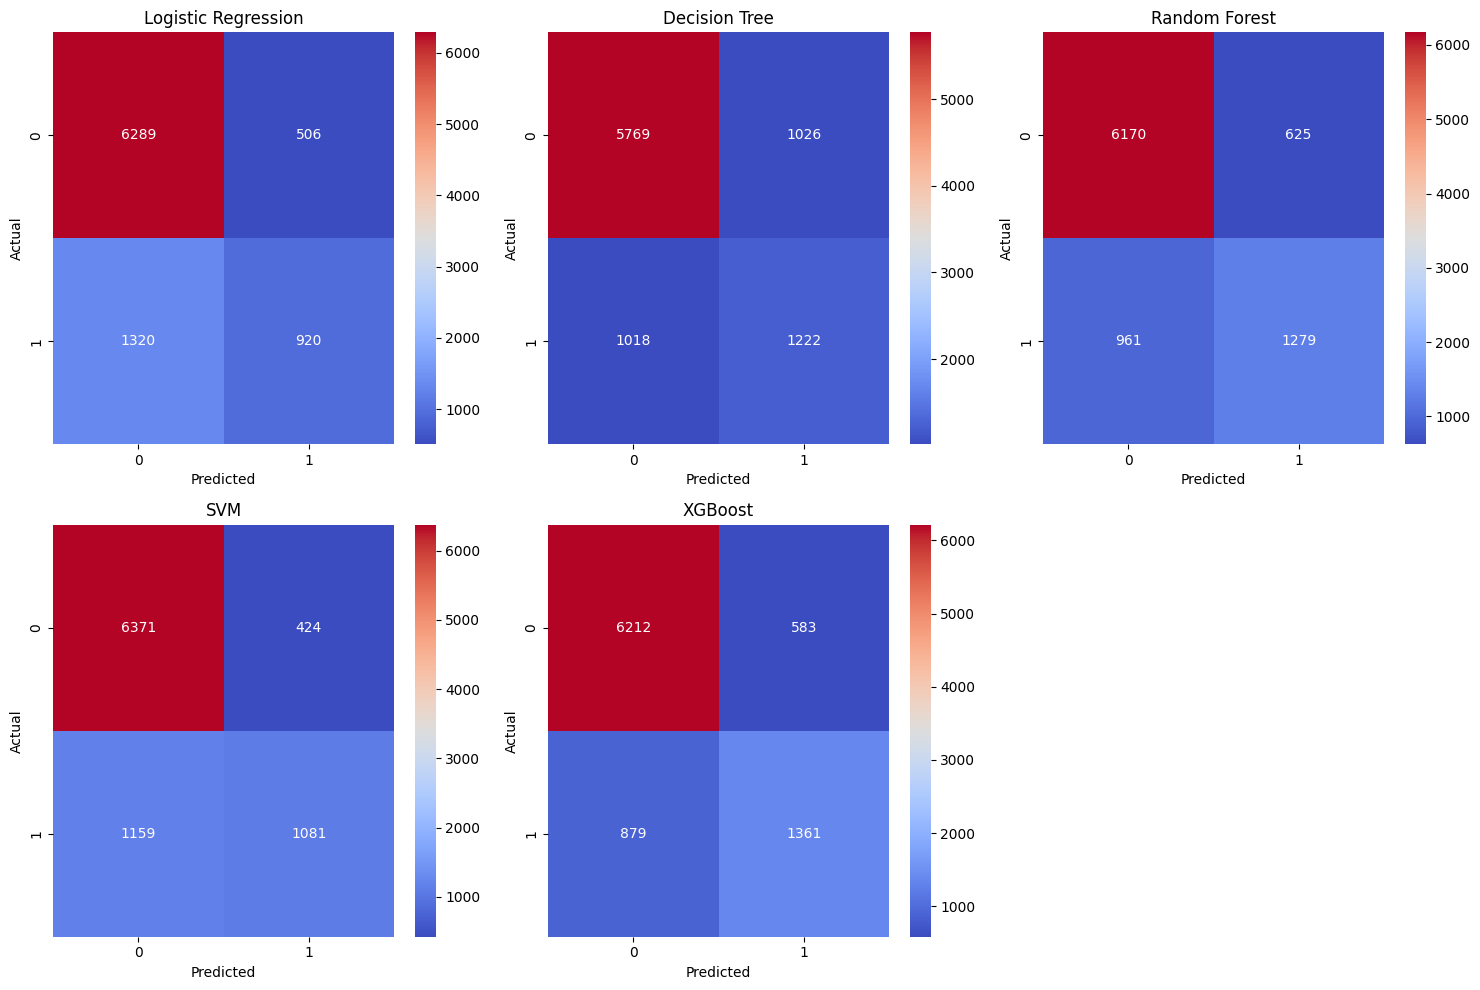

In [ ]:
from sklearn.metrics import confusion_matrix

plt.figure(figsize=(15,10))

for i, (name, model) in enumerate(models.items(), 1):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    plt.subplot(2, 3, i)
    sns.heatmap(cm, annot=True, fmt="d", cmap="coolwarm")
    plt.title(name)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

plt.tight_layout()
plt.show()

In [ ]:
import plotly.express as px

fig = px.bar(
    results_df,
    x="Model",
    y=["Accuracy", "Precision", "Recall", "F1 Score"],
    barmode="group",
    color_discrete_sequence=["#00f5d4", "#ff006e", "#8338ec", "#ffbe0b"],
    title="Model Performance Comparison"
)

fig.update_layout(
    plot_bgcolor="#0f172a",
    paper_bgcolor="#0f172a",
    font=dict(color="white"),
    xaxis_tickangle=-30
)

fig.show()

In [ ]:
best_model = results_df.sort_values(by="Accuracy", ascending=False).iloc[0]

print(" Best Model:")
print(best_model)

 Best Model:
Model         XGBoost
Accuracy     0.838185
Precision    0.700103
Recall       0.607589
F1 Score     0.650574
Name: 4, dtype: object


In [ ]:
import plotly.express as px

fig = px.bar(
    results_df,
    x="Model",
    y="Accuracy",
    color="Accuracy",
    text=results_df["Accuracy"].round(3),
    title="Best Model Selection Based on Accuracy",
    color_continuous_scale="Viridis"
)

fig.add_annotation(
    x=best_model["Model"],
    y=best_model["Accuracy"],
    text="Best Model",
    showarrow=True,
    arrowhead=2,
    font=dict(size=14, color="red")
)

fig.update_layout(
    plot_bgcolor="#0f172a",
    paper_bgcolor="#0f172a",
    font=dict(color="white"),
    title_font=dict(size=22)
)

fig.show()

In [ ]:
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

for name, model in models.items():

    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:,1]
    else:
        y_prob = model.decision_function(X_test)

    auc = roc_auc_score(y_test, y_prob)

    print(f"{name} AUC = {auc:.4f}")

Logistic Regression AUC = 0.8161
Decision Tree AUC = 0.6975
Random Forest AUC = 0.8706
SVM AUC = 0.8631
XGBoost AUC = 0.8887


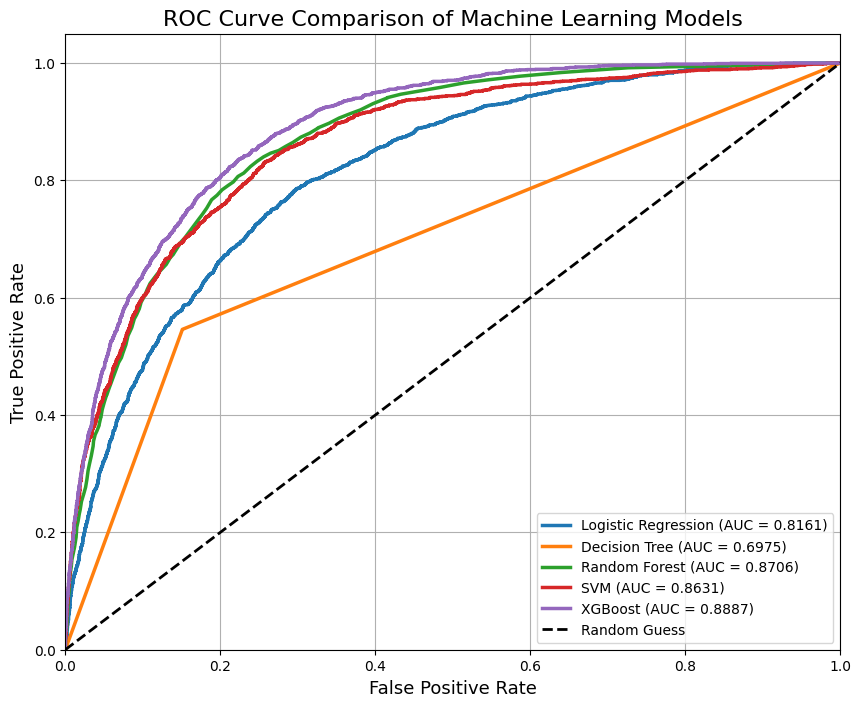

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 8))

for name, model in models.items():

    # Get prediction scores
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
    elif hasattr(model, "decision_function"):
        y_score = model.decision_function(X_test)
    else:
        continue

    # ROC Curve
    fpr, tpr, _ = roc_curve(y_test, y_score)

    # AUC Score
    auc = roc_auc_score(y_test, y_score)

    # Plot ROC
    plt.plot(
        fpr,
        tpr,
        linewidth=2.5,
        label=f"{name} (AUC = {auc:.4f})"
    )

# Random Guess
plt.plot(
    [0, 1],
    [0, 1],
    'k--',
    linewidth=2,
    label="Random Guess"
)

plt.title("ROC Curve Comparison of Machine Learning Models", fontsize=16)
plt.xlabel("False Positive Rate", fontsize=13)
plt.ylabel("True Positive Rate", fontsize=13)
plt.xlim(0, 1)
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend(loc="lower right")

plt.show()

In [ ]:
from sklearn.model_selection import cross_val_score

for name, model in models.items():

    scores = cross_val_score(
        model,
        X,
        y,
        cv=5,
        scoring="accuracy"
    )

    print(name)
    print(scores)
    print(scores.mean())

Logistic Regression
[0.78550083 0.78837853 0.78693968 0.78981738 0.79302712]
0.788732706142778
Decision Tree
[0.77387936 0.77288323 0.77675706 0.76978417 0.77343664]
0.7733480907581628
Random Forest
[0.81848367 0.82191478 0.82114001 0.82368567 0.82169341]
0.8213835085777532
SVM
[0.75207526 0.75207526 0.75207526 0.75196458 0.75196458]
0.7520309905921417
XGBoost
[0.82888766 0.83076923 0.83065855 0.83353625 0.83796348]
0.8323630326508024


In [ ]:
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier

param_grid = {
    'max_depth':[3,5,7],
    'learning_rate':[0.01,0.1],
    'n_estimators':[100,200]
}

grid = GridSearchCV(
    XGBClassifier(
        random_state=42,
        eval_metric='logloss'
    ),
    param_grid,
    cv=5,
    scoring='accuracy'
)

grid.fit(X_train,y_train)

best_model = grid.best_estimator_

print(grid.best_params_)

{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}


In [ ]:
pip install shap lime fairlearn

SHAP EXPLAINABILITY

SHAP Summary Plot


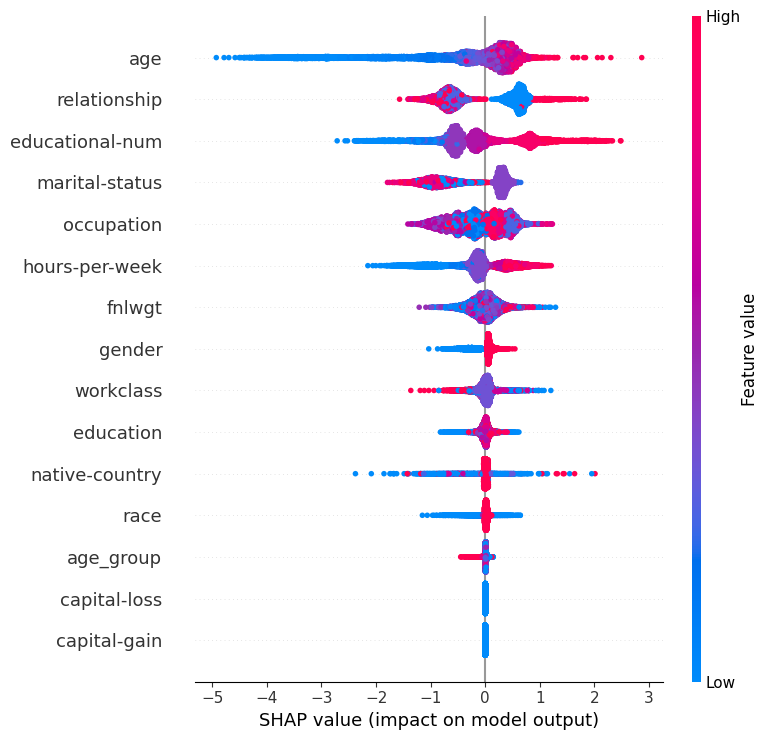


SHAP Feature Importance


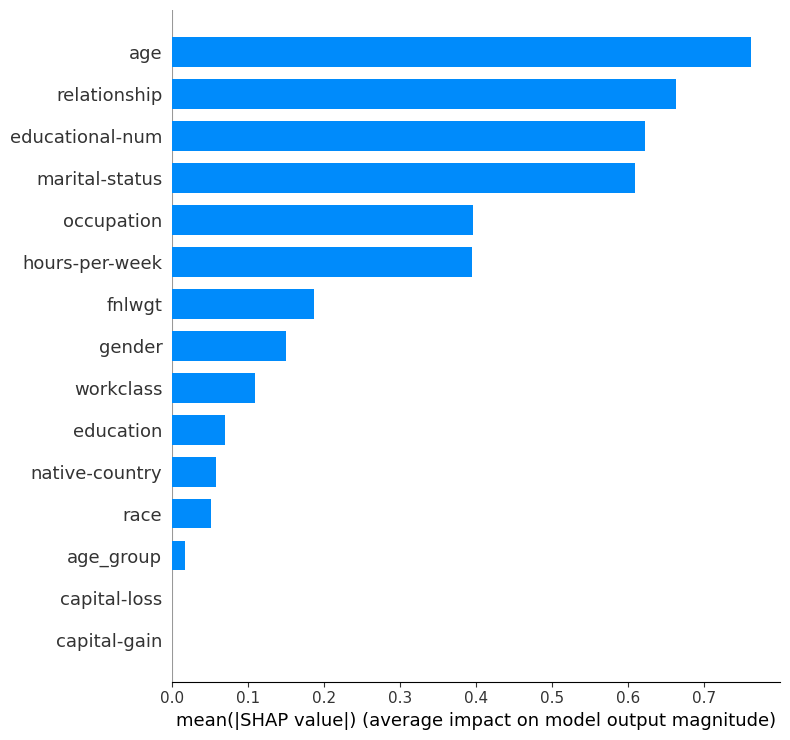

In [ ]:
import shap
import lime
import lime.lime_tabular
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fairlearn.metrics import (
    MetricFrame,
    selection_rate,
    demographic_parity_difference,
    equalized_odds_difference
)
from sklearn.metrics import accuracy_score

# ==========================
# SHAP (XGBoost)
# ==========================

print("="*60)
print("SHAP EXPLAINABILITY")
print("="*60)

xgb_model = models["XGBoost"]

explainer = shap.TreeExplainer(xgb_model)

shap_values = explainer.shap_values(X_test)

print("\nSHAP Summary Plot")
shap.summary_plot(
    shap_values,
    X_test,
    feature_names=X.columns.tolist()
)

print("\nSHAP Feature Importance")
shap.summary_plot(
    shap_values,
    X_test,
    feature_names=X.columns.tolist(),
    plot_type="bar"
)

LIME EXPLAINABILITY


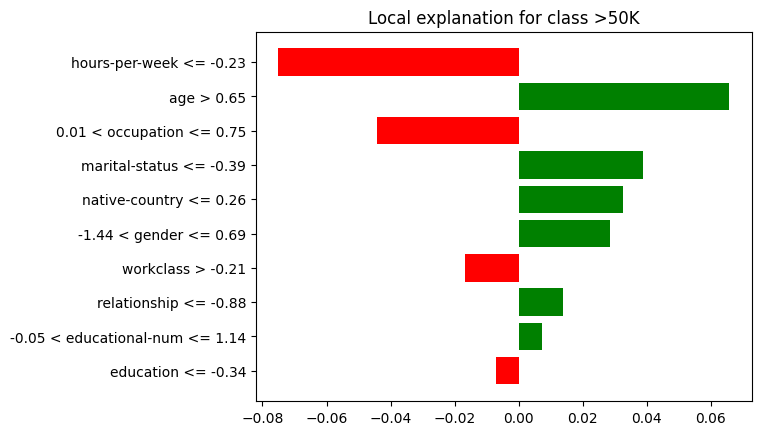

In [ ]:
# ==========================
# LIME
# ==========================

print("="*60)
print("LIME EXPLAINABILITY")
print("="*60)

# Convert to NumPy arrays if needed
X_train_np = np.asarray(X_train)
X_test_np = np.asarray(X_test)

lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train_np,
    feature_names=X.columns.tolist(),
    class_names=["<=50K", ">50K"],
    mode="classification"
)

sample = 0

lime_exp = lime_explainer.explain_instance(
    X_test_np[sample],
    xgb_model.predict_proba,
    num_features=10
)

fig = lime_exp.as_pyplot_figure()
plt.show()

In [ ]:
# ==========================
# Hybrid Comparison
# ==========================

print("="*60)
print("HYBRID SHAP + LIME COMPARISON")
print("="*60)

shap_importance = pd.DataFrame({
    "Feature": X.columns,
    "SHAP Importance": np.abs(shap_values).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    by="SHAP Importance",
    ascending=False
)

lime_importance = pd.DataFrame(
    lime_exp.as_list(),
    columns=["Feature","LIME Weight"]
)

print("\nTop SHAP Features")
print(shap_importance.head(10))

print("\nLIME Local Explanation")
print(lime_importance)

# ==========================
# Fairness Analysis
# ==========================

print("="*60)
print("FAIRNESS ANALYSIS")
print("="*60)

# Retrieve the original label-encoded 'gender' column for the test set
# Convert to numpy array for robustness with fairlearn
sensitive_feature = df_model.loc[y_test.index, 'gender'].values

# Ensure y_test is also a numpy array for consistency with y_pred in fairlearn
y_test_np = y_test.values

y_pred = xgb_model.predict(X_test)

metric_frame = MetricFrame(
    metrics={
        "Accuracy": accuracy_score,
        "Selection Rate": selection_rate
    },
    y_true=y_test_np, # Use the numpy array version
    y_pred=y_pred,
    sensitive_features=sensitive_feature
)

print("\nMetrics by Group")
print(metric_frame.by_group)

print("\nOverall Metrics")
print(metric_frame.overall)

dp = demographic_parity_difference(
    y_true=y_test_np, # Use the numpy array version
    y_pred=y_pred,
    sensitive_features=sensitive_feature
)

eo = equalized_odds_difference(
    y_true=y_test_np, # Use the numpy array version
    y_pred=y_pred,
    sensitive_features=sensitive_feature
)

print("\nDemographic Parity Difference :", dp)
print("Equal Opportunity Difference :", eo)

print("\nAnalysis Completed Successfully!")

HYBRID SHAP + LIME COMPARISON

Top SHAP Features
            Feature  SHAP Importance
0               age         0.761614
7      relationship         0.662700
4   educational-num         0.622528
5    marital-status         0.609388
6        occupation         0.396102
12   hours-per-week         0.394114
2            fnlwgt         0.186603
9            gender         0.150114
1         workclass         0.109295
3         education         0.069979

LIME Local Explanation
                           Feature  LIME Weight
0          hours-per-week <= -0.23    -0.075030
1                       age > 0.65     0.065768
2        0.01 < occupation <= 0.75    -0.044384
3          marital-status <= -0.39     0.038852
4           native-country <= 0.26     0.032423
5           -1.44 < gender <= 0.69     0.028481
6                workclass > -0.21    -0.016716
7            relationship <= -0.88     0.013895
8  -0.05 < educational-num <= 1.14     0.007334
9               education <= -0.34    -0

In [ ]:
print("\n Actual vs Predicted Values (Sample):\n")

for name, model in models.items():
    y_pred = model.predict(X_test)

    print(f"\n{name}:")
    comparison_df = pd.DataFrame({
        "Actual": y_test.values,
        "Predicted": y_pred
    })

    print(comparison_df.head(10))


 Actual vs Predicted Values (Sample):


Logistic Regression:
   Actual  Predicted
0       1          1
1       0          0
2       0          0
3       0          0
4       0          0
5       1          0
6       0          0
7       0          0
8       1          0
9       0          0

Decision Tree:
   Actual  Predicted
0       1          1
1       0          0
2       0          0
3       0          0
4       0          0
5       1          1
6       0          0
7       0          0
8       1          1
9       0          0

Random Forest:
   Actual  Predicted
0       1          1
1       0          1
2       0          0
3       0          0
4       0          0
5       1          0
6       0          1
7       0          0
8       1          1
9       0          0

SVM:
   Actual  Predicted
0       1          1
1       0          0
2       0          0
3       0          0
4       0          0
5       1          0
6       0          0
7       0          0
8       1         